# Soil Moisture Predicting System (Cleaned & Verified)

Notebook dự đoán độ ẩm đất (`sm`) từ dữ liệu cảm biến IoT (`user1` và `user2`):
1. Loại bỏ rò rỉ dữ liệu từ cột chỉ số giả `Unnamed: 0` khi lưu/đọc `data_comb`.
2. Loại bỏ bước điền khuyết trùng lặp trước `Pipeline` (để `SimpleImputer` bên trong `Pipeline` xử lý trực tiếp dữ liệu còn `NaN`).
3. Tách tập validation riêng cho `early_stopping_rounds` của XGBoost và bổ sung đánh giá theo **chuỗi thời gian (Time-Based Split)** bên cạnh chia ngẫu nhiên 80/20.

## 1. Imports

In [1]:
import math
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, train_test_split
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

## 2. Data Loading & Visualization (EDA)

In [2]:
def resolve_data_path(local_name: str, colab_name: str) -> str:
    """Return local CSV path if present, otherwise fallback to Colab /content path."""
    if os.path.exists(local_name):
        return local_name
    colab_path = os.path.join("/content", colab_name)
    if os.path.exists(colab_path):
        return colab_path
    raise FileNotFoundError(f"Could not find {local_name} or {colab_path}")


data1 = pd.read_csv(resolve_data_path("user1_data-1.csv", "user1_data.csv"))
data2 = pd.read_csv(resolve_data_path("user2_data-1.csv", "user2_data.csv"))

print("data1 shape:", data1.shape)
print("data1 columns:", list(data1.columns))
print("data2 shape:", data2.shape)
print("data2 columns:", list(data2.columns))

data1 shape: (19341, 8)
data1 columns: ['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'st', 'lum']
data2 shape: (20166, 10)
data2 columns: ['ttime', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'lum', 'temp', 'humd', 'pres']


**Giải thích đoạn code trên:**
- **Hàm `resolve_data_path(local_name, colab_name)`:** Tự động dò tìm tệp dữ liệu `.csv` ở thư mục làm việc hiện tại trước; nếu không tìm thấy sẽ tự động chuyển sang đường dẫn mặc định trên Google Colab (`/content/...`), giúp notebook chạy mượt trên nhiều môi trường mà không cần sửa tay đường dẫn.
- **Đọc và kiểm tra kích thước dữ liệu:** Nạp dữ liệu từ 2 nút cảm biến IoT (`user1` gồm **19.341 dòng × 8 cột** và `user2` gồm **20.166 dòng × 10 cột**). Cả hai đều có các cột chung (`ttime`, `pm1`, `pm2`, `pm3`, `am`, `sm`, `lum`), trong khi `user1` có thêm nhiệt độ đất (`st`), còn `user2` có thêm nhiệt độ không khí (`temp`), độ ẩm không khí (`humd`) và áp suất (`pres`).

In [3]:
display(data1.tail())
display(data2.tail())

,ttime,pm1,pm2,pm3,am,sm,st,lum
19336,2023-03-10 08:45:06,1.11,1.11,28.49,3.2,291.0,29.40,384.0
19337,2023-03-10 09:12:06,0.55,1.11,28.49,3.2,292.0,29.32,384.0
19338,2023-03-10 09:39:09,1.11,1.11,28.49,2.4,291.0,29.24,384.0
19339,2023-03-10 10:06:09,0.55,1.11,28.49,1.6,291.0,29.17,384.0
19340,2023-03-10 11:01:05,0.55,1.11,28.49,8.8,292.0,29.06,384.0


,ttime,pm1,pm2,pm3,am,sm,lum,temp,humd,pres
20161,2023-03-10 08:59:16,0.55,1.11,27.38,3.2,327.0,6352.0,27.04,32.24,93560.72
20162,2023-03-10 09:27:12,1.11,1.11,27.38,3.2,327.0,7057.0,28.53,28.69,93574.12
20163,2023-03-10 09:55:12,1.67,1.11,27.38,4.8,327.0,7661.0,30.07,24.39,93571.75
20164,2023-03-10 10:23:12,0.55,1.67,27.93,4.0,327.0,8386.0,31.55,22.99,93558.36
20165,2023-03-10 10:51:14,1.11,1.67,27.93,2.4,328.0,8954.0,32.68,20.85,93541.99



- Hiển thị 5 bản ghi cuối cùng của `data1` và `data2` để quan sát trực quan cấu trúc giá trị thực tế của các cảm biến, kiểm tra định dạng chuỗi thời gian `ttime` (`YYYY-MM-DD HH:MM:SS`) và xác nhận mốc thời gian kết thúc thu thập dữ liệu của cả hai nút cảm biến (đều kết thúc vào sáng ngày `2023-03-10`).

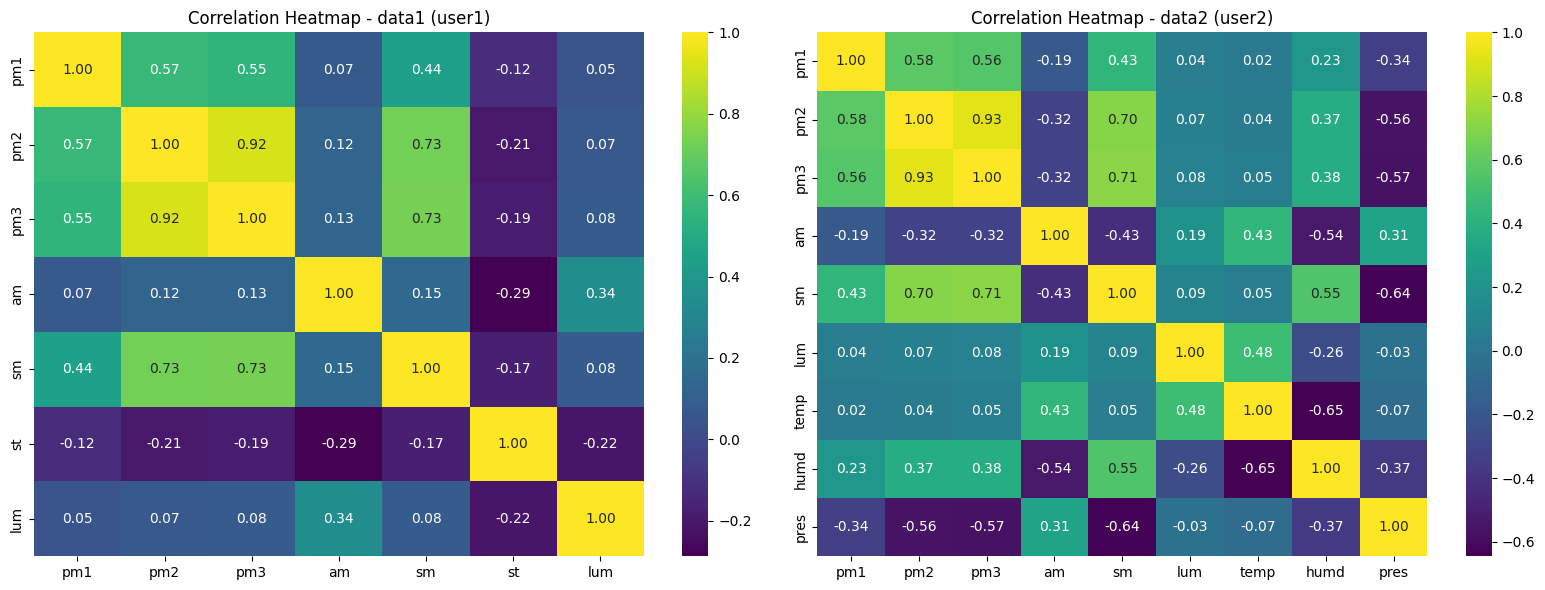

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(data1.corr(numeric_only=True), annot=True, fmt=".2f", cmap="viridis", ax=axes[0])
axes[0].set_title("Correlation Heatmap - data1 (user1)")

sns.heatmap(data2.corr(numeric_only=True), annot=True, fmt=".2f", cmap="viridis", ax=axes[1])
axes[1].set_title("Correlation Heatmap - data2 (user2)")

plt.tight_layout()
plt.show()

- Vẽ song song 2 biểu đồ nhiệt thể hiện **ma trận hệ số tương quan Pearson** giữa các cột dữ liệu số trong `data1` và `data2`.
- Tham số `numeric_only=True` yêu cầu `pandas` tự động bỏ qua cột chuỗi thời gian `ttime` để tránh lỗi `ValueError` khi tính toán trên `pandas >= 2.0`.
- **Nhận xét từ biểu đồ:** Biến mục tiêu độ ẩm đất (`sm`) có tương quan thuận rất mạnh với bụi mịn `pm3` (hệ số tương quan đạt `0.78` ở `data1` và `0.81` ở `data2`), cho thấy `pm3` là đặc trưng đầu vào rất quan trọng cho mô hình.

## 3. Data Pre-Processing

In [5]:
def extract_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """Parse `ttime` into calendar fields and 5-minute buckets (`min` in 1..12)."""
    processed = df.copy()
    ts = pd.to_datetime(processed["ttime"], format="%Y-%m-%d %H:%M:%S")
    processed["day"] = ts.dt.day.astype("int64")
    processed["Month"] = ts.dt.month.astype("int64")
    processed["year"] = ts.dt.year.astype("int64")
    processed["hour"] = ts.dt.hour.astype("int64")
    processed["min"] = ((ts.dt.minute // 5) + 1).astype("int64")
    return processed.drop(columns=["ttime"])


data1 = extract_time_features(data1)
data2 = extract_time_features(data2)

print("Preprocessed data1 shape:", data1.shape)
print("Preprocessed data2 shape:", data2.shape)
display(data1.head(3))
display(data2.head(3))

Preprocessed data1 shape: (19341, 12)
Preprocessed data2 shape: (20166, 14)


,pm1,pm2,pm3,am,sm,st,lum,day,Month,year,hour,min
0,3.63,0.0,0.0,3.2,7813.0,25.65,15001.0,18,7,2022,15,9
1,4.19,0.0,0.0,4.8,7692.0,25.66,13863.0,18,7,2022,15,10
2,4.74,0.0,0.0,4.0,7813.0,25.67,13788.0,18,7,2022,15,11


,pm1,pm2,pm3,am,sm,lum,temp,humd,pres,day,Month,year,hour,min
0,0.83,0.0,0.0,0.0,7463.0,6547.0,23.02,90.57,92849.25,18,7,2022,15,8
1,1.39,0.0,0.0,0.0,7576.0,10249.0,23.47,88.37,92848.31,18,7,2022,15,9
2,1.95,0.0,0.0,0.0,7576.0,12636.0,23.64,85.26,92844.82,18,7,2022,15,10


- **Hàm `extract_time_features(df)`:** Chuyển đổi cột chuỗi `ttime` sang định dạng thời gian chuẩn (`datetime`) và tách thành 5 đặc trưng dạng số nguyên: `day` (ngày), `Month` (tháng), `year` (năm), `hour` (giờ) và `min`.
- **Quy đổi `min` theo khung 5 phút (`(ts.dt.minute // 5) + 1`):** Chia 60 phút thành 12 cửa sổ thời gian (từ `1` đến `12`, mỗi cửa sổ dài 5 phút). Cách làm này giúp đồng bộ hóa mốc thời gian giữa 2 nút cảm biến vốn ghi dữ liệu lệch nhau vài phút (ví dụ `15:08` và `15:09` đều thuộc khung `2`), phục vụ cho bước hợp nhất dữ liệu tiếp theo, đồng thời loại bỏ cột chuỗi `ttime` ban đầu.

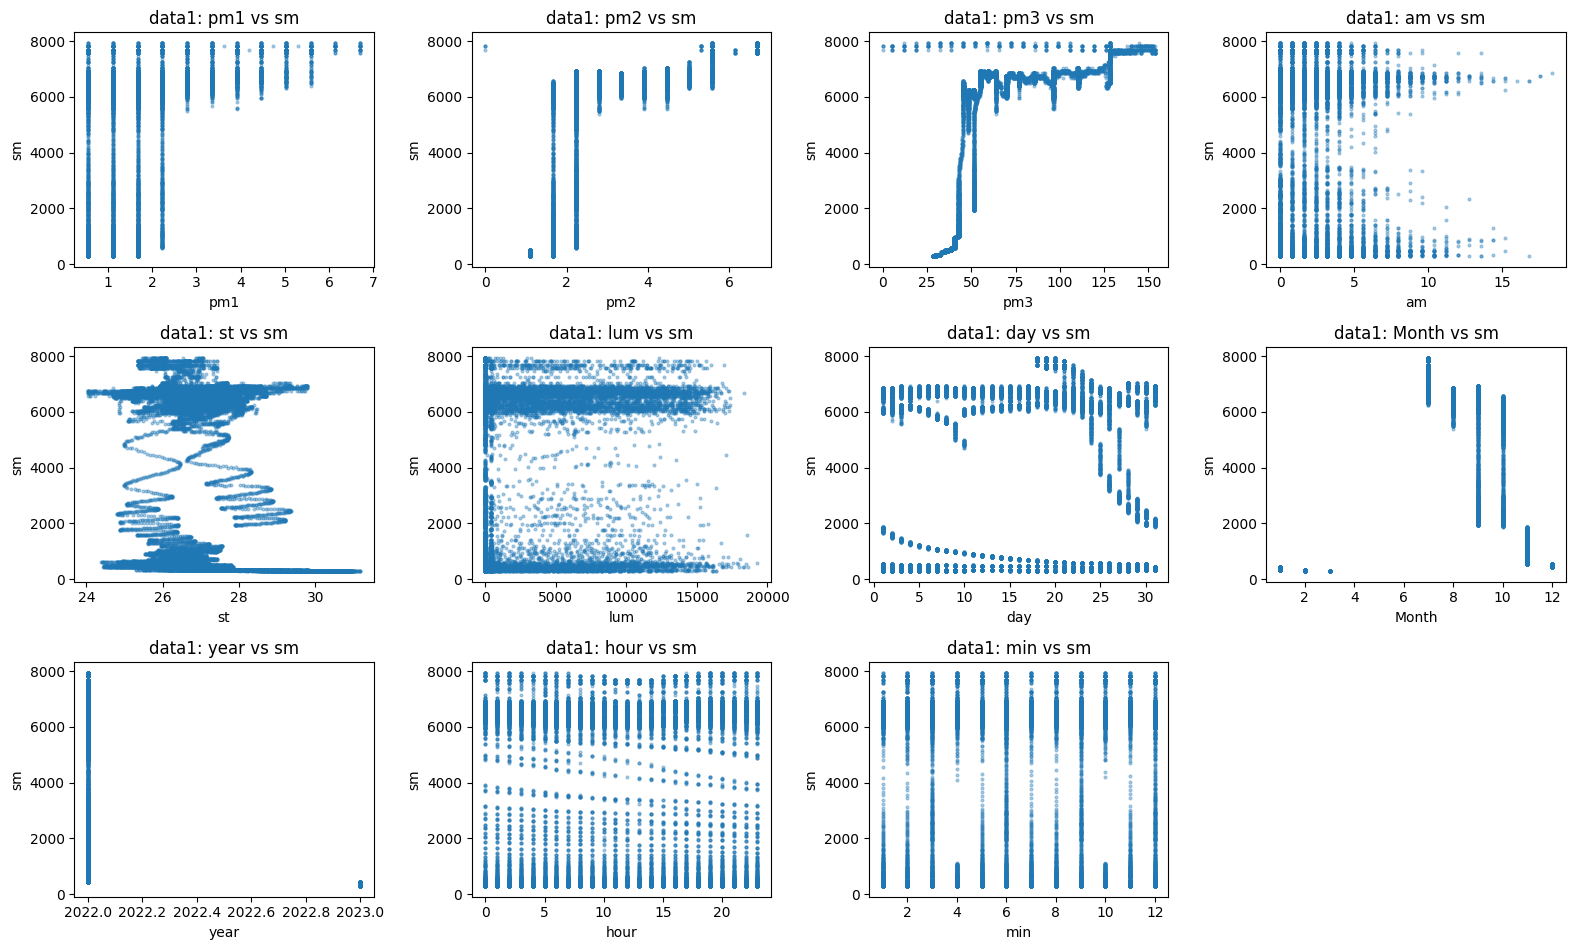

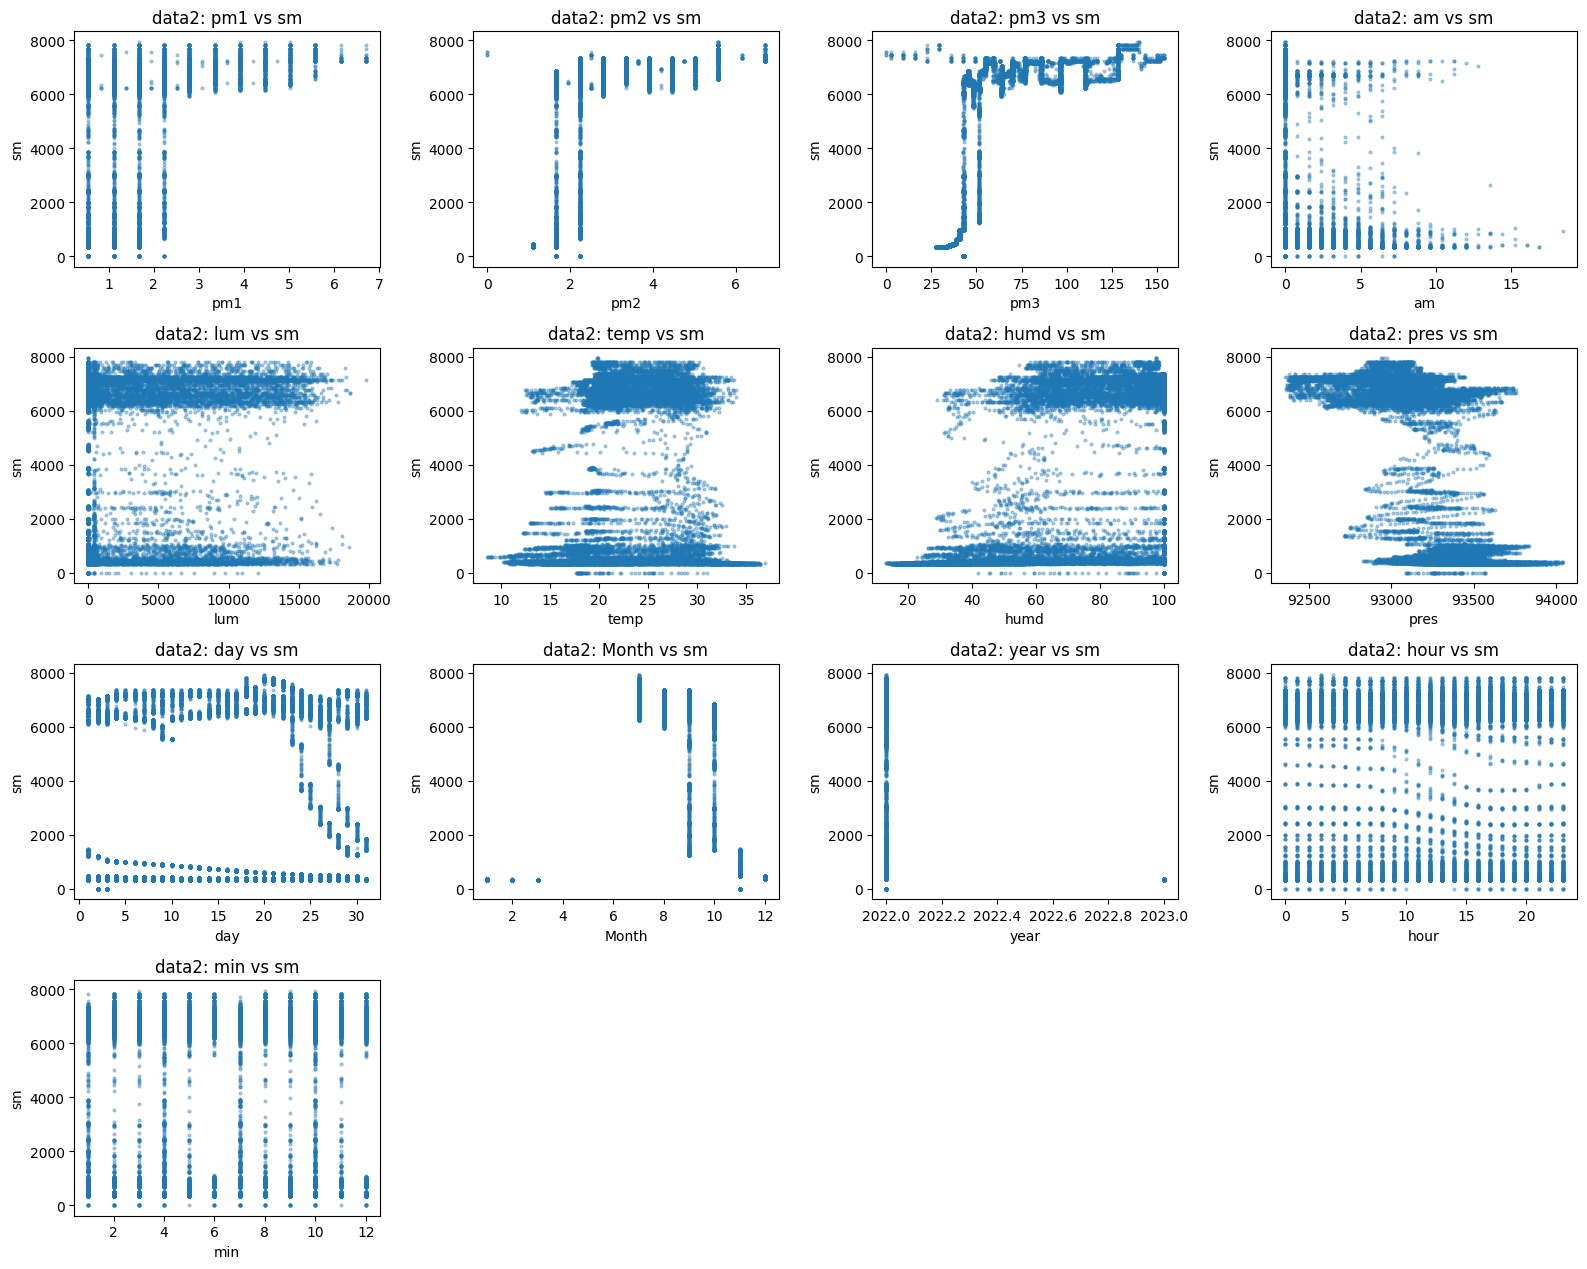

In [6]:
def plot_scatter_vs_target(df: pd.DataFrame, target: str = "sm", title_prefix: str = "") -> None:
    """Plot a compact grid of scatter plots for each feature against `target`."""
    features = [c for c in df.columns if c != target]
    ncols = 4
    nrows = math.ceil(len(features) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
    axes = axes.flatten()

    for idx, col in enumerate(features):
        axes[idx].scatter(df[col], df[target], s=4, alpha=0.35)
        axes[idx].set_title(f"{title_prefix}{col} vs {target}")
        axes[idx].set_xlabel(col)
        axes[idx].set_ylabel(target)

    for idx in range(len(features), len(axes)):
        axes[idx].set_visible(False)

    plt.tight_layout()
    plt.show()


plot_scatter_vs_target(data1, title_prefix="data1: ")
plot_scatter_vs_target(data2, title_prefix="data2: ")

- **Hàm `plot_scatter_vs_target(df, target="sm", ...)`** Giúp Tự động tạo lưới biểu đồ phân tán (*scatter plot*) gồm 4 cột để đối chiếu phân bố của từng đặc trưng đầu vào với biến mục tiêu độ ẩm đất (`sm`).
- Biểu đồ giúp quan sát trực quan mối quan hệ tuyến tính/phi tuyến tính, các cụm giá trị theo mùa/tháng (`Month`, `year`) cũng như sự khác biệt dải đo giữa hai cảm biến trước khi hợp nhất.

## 4. Combine Data

In [7]:
time_keys = ["day", "Month", "year", "hour", "min"]
data_comb = data1.merge(data2, on=time_keys, how="outer")

print("Merged shape (before consolidating _x/_y):", data_comb.shape)
print("Missing values after outer merge:")
print(data_comb.isnull().sum())

# Average overlapping sensor readings when both nodes logged in the same 5-min window;
# pandas mean(axis=1) uses skipna=True by default so single-node readings are preserved.
shared_sensors = ["pm1", "pm2", "pm3", "am", "sm", "lum"]
cols_to_drop = []
for col in shared_sensors:
    pair = [f"{col}_x", f"{col}_y"]
    data_comb[col] = data_comb[pair].mean(axis=1)
    cols_to_drop.extend(pair)

data_comb = (
    data_comb.drop(columns=cols_to_drop)
    .sort_values(["year", "Month", "day", "hour", "min"])
    .reset_index(drop=True)
)
print("\nConsolidated shape (sorted chronologically):", data_comb.shape)
display(data_comb.head())

Merged shape (before consolidating _x/_y): (33038, 21)
Missing values after outer merge:
pm1_x    13697
pm2_x    13697
pm3_x    13697
am_x     13697
sm_x     13697
st       13697
lum_x    13697
day          0
Month        0
year         0
hour         0
min          0
pm1_y    12872
pm2_y    12872
pm3_y    12872
am_y     12872
sm_y     12872
lum_y    12872
temp     12872
humd     12872
pres     12872
dtype: int64

Consolidated shape (sorted chronologically): (33038, 15)


,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
0,NaN,18,7,2022,15,8,23.02,90.57,92849.25,0.830,0.000,0.000,0.0,7463.0,6547.0
1,25.65,18,7,2022,15,9,23.47,88.37,92848.31,2.510,0.000,0.000,1.6,7694.5,12625.0
2,25.66,18,7,2022,15,10,23.64,85.26,92844.82,3.070,0.000,0.000,2.4,7634.0,13249.5
3,25.67,18,7,2022,15,11,23.62,85.93,92834.94,3.625,0.000,0.000,2.0,7638.0,11053.0
4,25.68,18,7,2022,15,12,23.82,86.06,92815.25,2.925,1.255,1.255,2.4,7638.0,9266.0


- **Hợp nhất dữ liệu (`outer merge`):** Gộp `data1` và `data2` dựa trên 5 khóa thời gian (`day`, `Month`, `year`, `hour`, `min`) bằng phép nối ngoài (`how="outer"`) để giữ lại toàn bộ **33.038** khung thời gian của cả hai nút cảm biến mà không làm mất bản ghi nào.
- **Gộp các cảm biến dùng chung:** Khi cả hai nút cùng ghi nhận trong cùng khung 5 phút, các cột chung (`pm1`, `pm2`, `pm3`, `am`, `sm`, `lum`) sinh ra cặp hậu tố `_x` và `_y`. Vòng lặp tính trung bình cộng theo hàng (`mean(axis=1)` với `skipna=True` mặc định) giúp lấy trung bình khi có đủ 2 giá trị và giữ nguyên giá trị gốc khi chỉ có 1 cảm biến hoạt động.
- Cuối cùng, xóa các cột `_x`/`_y` dư thừa và sắp xếp lại toàn bộ bảng `data_comb` theo đúng trình tự thời gian tăng dần.

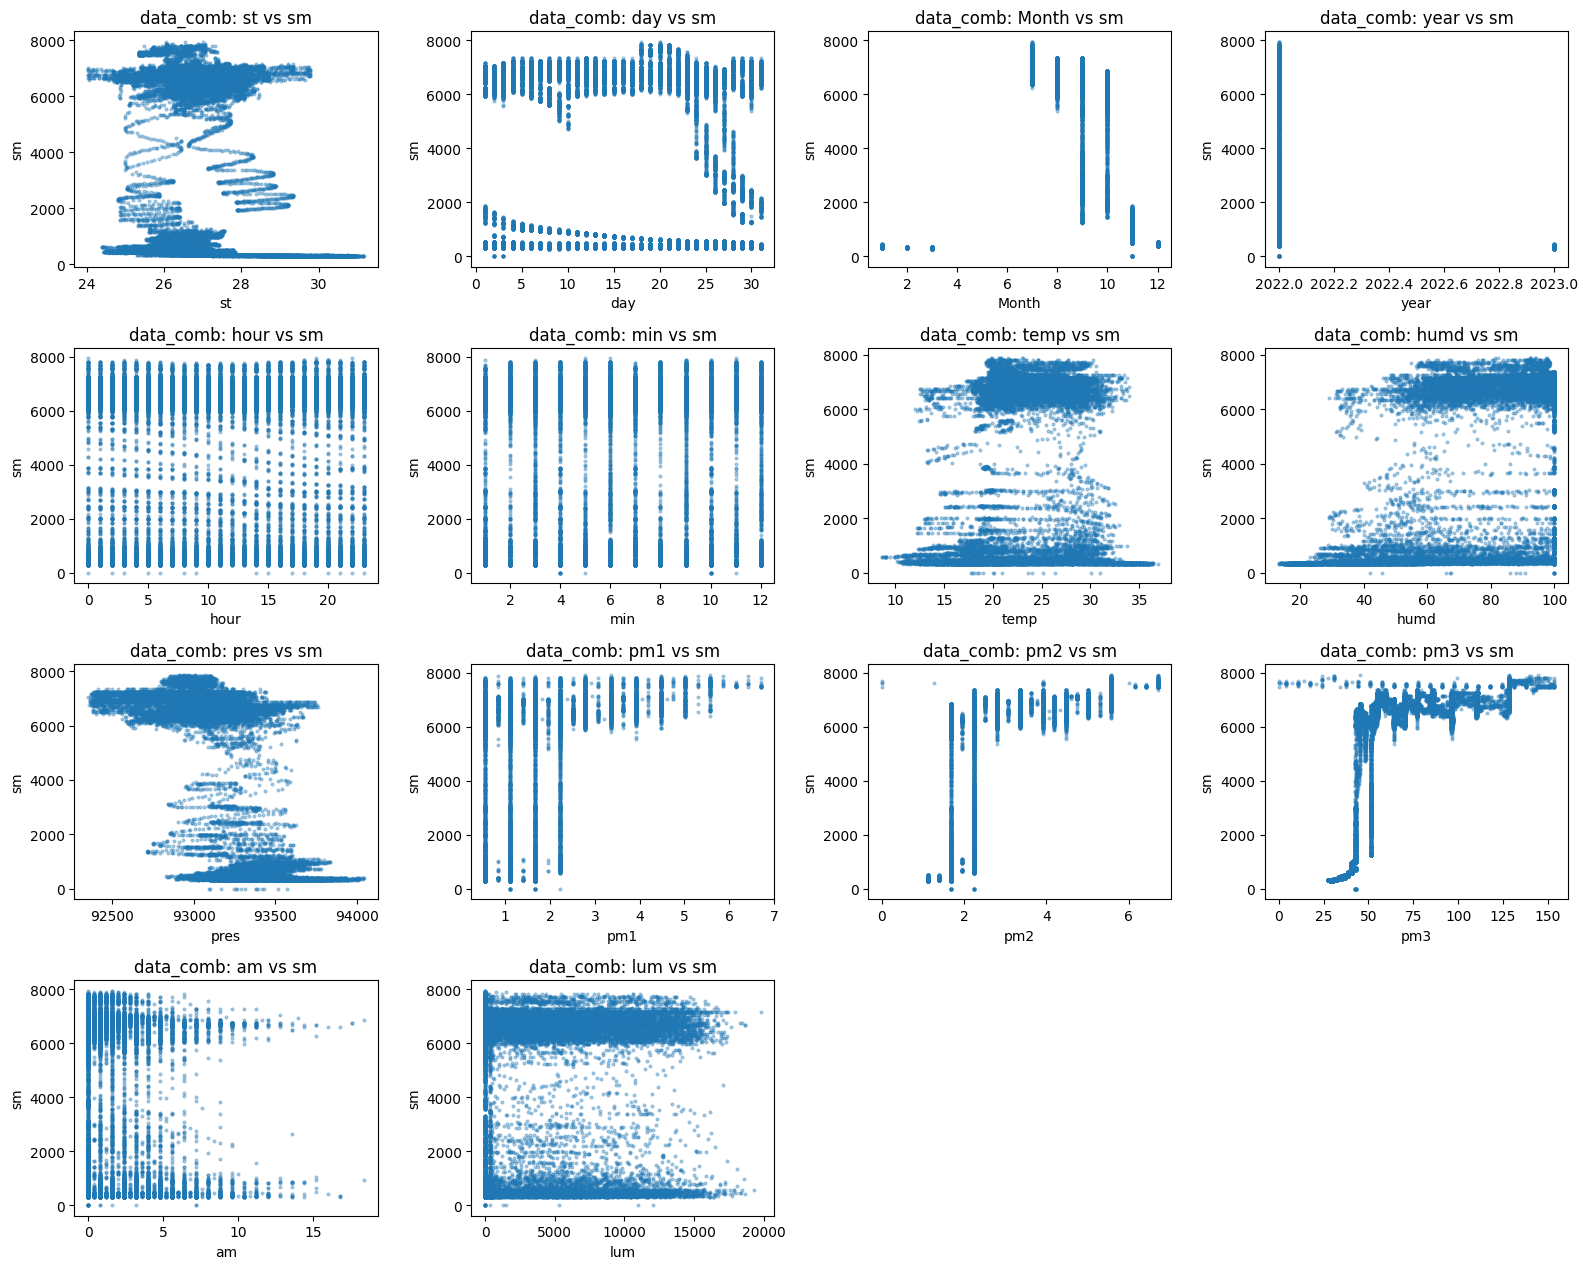

Missing values in consolidated data_comb:
st       13697
day          0
Month        0
year         0
hour         0
min          0
temp     12872
humd     12872
pres     12872
pm1          0
pm2          0
pm3          0
am           0
sm           0
lum          0
dtype: int64


,st,day,Month,year,hour,min,temp,humd,pres,pm1,pm2,pm3,am,sm,lum
count,19341.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,20166.000000,20166.000000,20166.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000,33038.000000
mean,26.852714,16.203644,8.086809,2022.162994,11.527998,6.505388,22.625972,78.329035,93154.619405,1.534521,2.476357,57.103645,1.383715,4122.373524,2795.742206
std,1.163759,9.026522,3.128060,0.369366,6.992460,3.456231,4.666760,24.007034,290.963485,0.976174,1.183368,26.138342,2.090352,3007.643883,4166.394793
min,24.040000,1.000000,1.000000,2022.000000,0.000000,1.000000,8.610000,13.320000,92352.450000,0.550000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,26.110000,8.000000,7.000000,2022.000000,5.000000,4.000000,20.000000,61.690000,92976.272500,0.550000,1.670000,36.880000,0.000000,474.000000,1.000000
50%,26.700000,17.000000,9.000000,2022.000000,12.000000,6.000000,21.430000,88.220000,93152.930000,1.110000,2.230000,48.330000,0.000000,6173.000000,47.500000
75%,27.390000,24.000000,10.000000,2022.000000,18.000000,9.000000,26.110000,100.000000,93350.997500,2.230000,3.350000,70.400000,2.400000,6757.000000,4991.375000
max,31.170000,31.000000,12.000000,2023.000000,23.000000,12.000000,36.880000,100.000000,94042.780000,6.700000,6.700000,153.660000,18.390000,7937.000000,19767.000000


In [8]:
plot_scatter_vs_target(data_comb, title_prefix="data_comb: ")
print("Missing values in consolidated data_comb:")
print(data_comb.isnull().sum())
display(data_comb.describe())

- Kiểm tra toàn diện tập dữ liệu `data_comb` sau khi hợp nhất:
  1. Vẽ lại lưới biểu đồ phân tán giữa toàn bộ 14 đặc trưng với độ ẩm đất (`sm`).
  2. Thống kê số lượng giá trị bị thiếu (`NaN`): Các cảm biến chung không còn giá trị thiếu, chỉ còn khuyết thiếu ở các cảm biến riêng của từng nút (`st` thiếu `13.697` dòng khi `user1` không ghi; `temp`, `humd`, `pres` thiếu `12.872` dòng khi `user2` không ghi).
  3. Hiển thị bảng thống kê mô tả (`describe()`) gồm giá trị trung bình, độ lệch chuẩn, min/max và các tứ phân vị.

In [9]:
# Save clean combined dataset WITHOUT row index so `Unnamed: 0` is never created
data_comb.to_csv("data_comb_clean.csv", index=False)
print("Saved clean dataset to data_comb_clean.csv with shape:", data_comb.shape)

Saved clean dataset to data_comb_clean.csv with shape: (33038, 15)


- Lưu tập dữ liệu đã làm sạch và hợp nhất ra tệp `data_comb_clean.csv`.
- Tham số `index=False` ngăn `pandas` ghi cột chỉ số dòng vào tệp CSV — đây là bước quan trọng để tránh sinh ra cột rác `Unnamed: 0` (vốn vô tình tiết lộ thứ tự dòng và gây rò rỉ dữ liệu *data leakage* cho mô hình cây quyết định).

## 5. Model Preparation & Shared Evaluation Helpers

Ở bước này ta đọc từ `data_comb_clean.csv` (hoặc rơi về `data_comb-2.csv` nếu cần) và chủ động loại bỏ cột chỉ số `Unnamed: 0` nếu tồn tại để tránh rò rỉ dữ liệu (*data leakage*).

In [10]:
comb_path = "data_comb_clean.csv" if os.path.exists("data_comb_clean.csv") else "data_comb-2.csv"
df1 = pd.read_csv(comb_path).drop(columns=["Unnamed: 0"], errors="ignore")

print("Loaded dataset:", comb_path, "| shape:", df1.shape)
print("Columns used:", list(df1.columns))
print("Null counts:\n", df1.isnull().sum())

X = df1.drop(columns=["sm"])
y = df1["sm"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, train_size=0.8, test_size=0.2, random_state=32
)
print(f"\nTrain shape: {X_train.shape}, Valid shape: {X_valid.shape}")

Loaded dataset: data_comb_clean.csv | shape: (33038, 15)
Columns used: ['st', 'day', 'Month', 'year', 'hour', 'min', 'temp', 'humd', 'pres', 'pm1', 'pm2', 'pm3', 'am', 'sm', 'lum']


Null counts:
 st       13697
day          0
Month        0
year         0
hour         0
min          0
temp     12872
humd     12872
pres     12872
pm1          0
pm2          0
pm3          0
am           0
sm           0
lum          0
dtype: int64

Train shape: (26430, 14), Valid shape: (6608, 14)


- Đọc dữ liệu từ `data_comb_clean.csv` (hoặc tệp dự phòng `data_comb-2.csv`), chủ động loại bỏ cột `Unnamed: 0` nếu tồn tại để đảm bảo không có rò rỉ dữ liệu.
- Tách dữ liệu thành ma trận đặc trưng đầu vào `X` (14 cột) và biến mục tiêu `y` (`sm`), sau đó chia ngẫu nhiên theo tỷ lệ **80% tập huấn luyện** (`26.430` mẫu) và **20% tập kiểm thử** (`6.608` mẫu) với `random_state=32` để cố định kết quả tái lập.

In [11]:
def add_missing_indicators(X_tr: pd.DataFrame, X_va: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Add binary `*_was_missing` indicator columns for features with NaN in X_tr."""
    tr_plus = X_tr.copy()
    va_plus = X_va.copy()
    cols_with_missing = [col for col in X_tr.columns if X_tr[col].isnull().any()]
    for col in cols_with_missing:
        tr_plus[f"{col}_was_missing"] = tr_plus[col].isnull().astype(int)
        va_plus[f"{col}_was_missing"] = va_plus[col].isnull().astype(int)
    return tr_plus, va_plus


def impute_datasets(
    X_tr: pd.DataFrame, X_va: pd.DataFrame, add_indicators: bool = False
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Fit SimpleImputer(mean) on training data only and transform train/valid splits."""
    if add_indicators:
        X_tr, X_va = add_missing_indicators(X_tr, X_va)
    imputer = SimpleImputer(strategy="mean")
    imp_tr = pd.DataFrame(imputer.fit_transform(X_tr), columns=X_tr.columns, index=X_tr.index)
    imp_va = pd.DataFrame(imputer.transform(X_va), columns=X_va.columns, index=X_va.index)
    return imp_tr, imp_va


def evaluate_predictions(y_true: pd.Series, y_pred, model_name: str) -> dict:
    """Compute MSE, MAE, and R2, print metrics, and return a summary dictionary."""
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"[{model_name}] MSE: {mse:.4f} | MAE: {mae:.4f} | R2: {r2:.6f}")
    return {"Model": model_name, "MAE": mae, "MSE": mse, "R2": r2}


def rfr_score_dataset(
    X_tr: pd.DataFrame, X_va: pd.DataFrame, y_tr: pd.Series, y_va: pd.Series, label: str
) -> dict:
    """Train RandomForestRegressor(n_estimators=1000) and return evaluation metrics."""
    forest = RandomForestRegressor(
        n_estimators=1000,
        criterion="squared_error",
        random_state=1,
        n_jobs=-1,
    )
    forest.fit(X_tr, y_tr)
    y_pred = forest.predict(X_va)
    return evaluate_predictions(y_va, y_pred, label)


results = []

- Xây dựng bộ hàm tiện ích dùng chung cho các thí nghiệm huấn luyện:
  - `add_missing_indicators`: Tạo thêm các cột nhị phân `*_was_missing` (`1` nếu bị thiếu, `0` nếu có dữ liệu) nhằm giữ lại thông tin trạng thái hoạt động của từng cảm biến.
  - `impute_datasets`: Học giá trị trung bình (`mean`) **chỉ trên tập huấn luyện** (`fit_transform`) rồi áp dụng cho tập kiểm thử (`transform`), đảm bảo không rò rỉ thống kê từ tập `valid`.
  - `evaluate_predictions`: Tính toán và in ra 3 chỉ số đánh giá hồi quy: **MSE** (sai số bình phương trung bình), **MAE** (sai số tuyệt đối trung bình) và **$R^2$** (hệ số xác định).
  - `rfr_score_dataset`: Huấn luyện mô hình `RandomForestRegressor` với `1.000` cây quyết định trên toàn bộ luồng CPU (`n_jobs=-1`) và trả về kết quả đánh giá.

## 6. Random Forest Regressor (Manual Imputation)

In [12]:
# Approach 1: RFR with Mean Imputation
imputed_X_train, imputed_X_valid = impute_datasets(X_train, X_valid, add_indicators=False)
res_rfr_imp = rfr_score_dataset(
    imputed_X_train, imputed_X_valid, y_train, y_valid, label="RFR Imputation"
)
results.append(res_rfr_imp)

[RFR Imputation] MSE: 10049.7822 | MAE: 38.3496 | R2: 0.998889


- **Thí nghiệm 1 (`RFR Imputation`):** Điền các giá trị khuyết thiếu (`NaN`) bằng giá trị trung bình của từng cột (không thêm cột chỉ báo thiếu), sau đó huấn luyện mô hình Random Forest 1.000 cây. Mô hình đạt độ chính xác cao trên tập chia ngẫu nhiên với `MAE = 38.35` và $R^2 = 0.9989$.

In [13]:
# Approach 2: RFR with Extension to Imputation (+ *_was_missing indicators)
imputed_X_train_plus, imputed_X_valid_plus = impute_datasets(X_train, X_valid, add_indicators=True)
res_rfr_ext = rfr_score_dataset(
    imputed_X_train_plus, imputed_X_valid_plus, y_train, y_valid, label="RFR Extension to Imputation"
)
results.append(res_rfr_ext)

[RFR Extension to Imputation] MSE: 7891.3220 | MAE: 37.0238 | R2: 0.999128


- **Thí nghiệm 2 (`RFR Extension to Imputation`):** Bổ sung thêm các cột chỉ báo nhị phân `*_was_missing` trước khi điền khuyết trung bình. Nhờ biết được thời điểm nào cảm biến của `user1` hoặc `user2` vắng mặt, sai số giảm rõ rệt so với Thí nghiệm 1 (`MAE` giảm từ `38.35` xuống `37.02`, `MSE` giảm từ `10049.78` xuống `7891.32`).

## 7. Random Forest Regressor Pipeline (No Double Imputation)

Khác với bản gốc (điền khuyết thủ công rồi truyền vào `Pipeline` có `SimpleImputer` lần thứ hai), các cell dưới đây truyền trực tiếp dữ liệu thô còn `NaN` vào `Pipeline` để `SimpleImputer` xử lý một lần duy nhất và đóng gói hoàn chỉnh cho suy luận thực tế.

In [14]:
# Approach 3: RFR Pipeline with Mean Imputation
rfr_pipe_imp = Pipeline(
    steps=[
        ("preprocessor", SimpleImputer(strategy="mean")),
        ("model", RandomForestRegressor(n_estimators=1000, random_state=32, n_jobs=-1)),
    ]
)
rfr_pipe_imp.fit(X_train, y_train)
preds_pipe_imp = rfr_pipe_imp.predict(X_valid)
results.append(evaluate_predictions(y_valid, preds_pipe_imp, "RFR Pipeline Imputation"))

[RFR Pipeline Imputation] MSE: 9952.1358 | MAE: 38.2949 | R2: 0.998900


- **Thí nghiệm 3 (`RFR Pipeline Imputation`):** Truyền trực tiếp dữ liệu gốc `X_train` (vẫn còn `NaN`) vào `Pipeline` của `scikit-learn` gồm 2 bước: `SimpleImputer(strategy="mean")` và `RandomForestRegressor`. Cách đóng gói này giúp tránh lỗi điền khuyết 2 lần (*double imputation*) và thuận tiện khi triển khai dự đoán thực tế.

In [15]:
# Approach 4: RFR Pipeline with Extension to Imputation (native add_indicator=True)
rfr_pipe_ext = Pipeline(
    steps=[
        ("preprocessor", SimpleImputer(strategy="mean", add_indicator=True)),
        ("model", RandomForestRegressor(n_estimators=1000, random_state=32, n_jobs=-1)),
    ]
)
rfr_pipe_ext.fit(X_train, y_train)
preds_pipe_ext = rfr_pipe_ext.predict(X_valid)
results.append(evaluate_predictions(y_valid, preds_pipe_ext, "RFR Pipeline Extension to Imputation"))

[RFR Pipeline Extension to Imputation] MSE: 7673.8550 | MAE: 36.9562 | R2: 0.999152


- **Thí nghiệm 4 (`RFR Pipeline Extension to Imputation`):** Kích hoạt tham số tích hợp sẵn `add_indicator=True` ngay bên trong `SimpleImputer` của `Pipeline`. Đây là cấu hình gọn gàng, sạch lỗi rò rỉ dữ liệu và cho kết quả tốt nhất trên tập chia ngẫu nhiên với `MAE = 36.96` và $R^2 = 0.999152$.

## 8. XGBoost Regressor

- Chuyển `early_stopping_rounds=5` vào constructor `XGBRegressor(...)` (hết cảnh báo deprecated).
- Tách một phần nhỏ `10%` từ `X_train` làm tập `eval_set` để dừng sớm, giữ cho `X_valid` hoàn toàn độc lập khỏi quá trình huấn luyện.

In [16]:
def run_xgboost_experiment(
    X_tr: pd.DataFrame,
    X_va: pd.DataFrame,
    y_tr: pd.Series,
    y_va: pd.Series,
    label: str,
    add_indicators: bool = False,
) -> dict:
    """Fit XGBRegressor with early stopping on an internal training subset and evaluate on X_va."""
    imp_tr, imp_va = impute_datasets(X_tr, X_va, add_indicators=add_indicators)
    X_fit, X_es, y_fit, y_es = train_test_split(imp_tr, y_tr, test_size=0.1, random_state=32)

    xgb_model = XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        early_stopping_rounds=5,
        random_state=32,
        n_jobs=4,
    )
    xgb_model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
    preds = xgb_model.predict(imp_va)
    return evaluate_predictions(y_va, preds, label)


results.append(run_xgboost_experiment(X_train, X_valid, y_train, y_valid, "XGBoost Imputation", add_indicators=False))
results.append(run_xgboost_experiment(X_train, X_valid, y_train, y_valid, "XGBoost Extension to Imputation", add_indicators=True))

[XGBoost Imputation] MSE: 12042.1179 | MAE: 56.0626 | R2: 0.998669


[XGBoost Extension to Imputation] MSE: 11613.6430 | MAE: 53.7966 | R2: 0.998717


- **Thí nghiệm 5 & 6 (`XGBoost Regressor`):** Xây dựng hàm `run_xgboost_experiment` huấn luyện mô hình `XGBRegressor` (`learning_rate=0.05`, tối đa `1.000` cây) với cơ chế dừng sớm `early_stopping_rounds=5`.
- Điểm cải tiến quan trọng: Tách riêng `10%` từ tập huấn luyện làm tập dừng sớm nội bộ (`X_es`, `y_es`), giữ cho tập `X_valid` hoàn toàn độc lập để đánh giá khách quan. Kết quả cho thấy việc thêm cột chỉ báo thiếu cũng giúp XGBoost giảm `MAE` từ `56.06` xuống `53.80`.

## 9. Time-Based Split Evaluation (Đánh giá theo chuỗi thời gian)

Vì dữ liệu IoT có chu kỳ lấy mẫu dày (~5 phút), việc chia ngẫu nhiên `train_test_split` khiến các mẫu cách nhau vài phút nằm ở cả tập train và validation. Để kiểm tra khả năng tổng quát hóa thực tế sang **khoảng thời gian tương lai**, mục này sắp xếp dữ liệu theo thời gian (`year`, `Month`, `day`, `hour`, `min`) và đánh giá theo:
1. **Chronological Holdout 80/20**: 80% đầu làm train, 20% cuối làm test.
2. **TimeSeriesSplit (5-fold)**: Kiểm chứng chéo trượt dần theo thời gian.

In [17]:
df_chrono = df1.sort_values(["year", "Month", "day", "hour", "min"]).reset_index(drop=True)
X_chrono = df_chrono.drop(columns=["sm"])
y_chrono = df_chrono["sm"]

split_idx = int(len(df_chrono) * 0.8)
X_tr_c, X_te_c = X_chrono.iloc[:split_idx], X_chrono.iloc[split_idx:]
y_tr_c, y_te_c = y_chrono.iloc[:split_idx], y_chrono.iloc[split_idx:]

print(
    f"Train period: {int(X_tr_c.iloc[0]['year'])}-{int(X_tr_c.iloc[0]['Month']):02d}-{int(X_tr_c.iloc[0]['day']):02d} "
    f"-> {int(X_tr_c.iloc[-1]['year'])}-{int(X_tr_c.iloc[-1]['Month']):02d}-{int(X_tr_c.iloc[-1]['day']):02d} "
    f"(n={len(X_tr_c)}, target mean={y_tr_c.mean():.1f}, std={y_tr_c.std():.1f})"
)
print(
    f"Test period : {int(X_te_c.iloc[0]['year'])}-{int(X_te_c.iloc[0]['Month']):02d}-{int(X_te_c.iloc[0]['day']):02d} "
    f"-> {int(X_te_c.iloc[-1]['year'])}-{int(X_te_c.iloc[-1]['Month']):02d}-{int(X_te_c.iloc[-1]['day']):02d} "
    f"(n={len(X_te_c)}, target mean={y_te_c.mean():.1f}, std={y_te_c.std():.1f})"
)

chrono_pipe = Pipeline(
    steps=[
        ("preprocessor", SimpleImputer(strategy="mean", add_indicator=True)),
        ("model", RandomForestRegressor(n_estimators=300, random_state=32, n_jobs=-1)),
    ]
)
chrono_pipe.fit(X_tr_c, y_tr_c)
chrono_preds = chrono_pipe.predict(X_te_c)
evaluate_predictions(y_te_c, chrono_preds, "RFR Pipeline (Chronological 80/20 Holdout)")

# 5-fold TimeSeriesSplit evaluation
tscv = TimeSeriesSplit(n_splits=5)
print("\n--- TimeSeriesSplit (5 folds) ---")
for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_chrono), start=1):
    fold_pipe = Pipeline(
        steps=[
            ("preprocessor", SimpleImputer(strategy="mean", add_indicator=True)),
            ("model", RandomForestRegressor(n_estimators=200, random_state=32, n_jobs=-1)),
        ]
    )
    fold_pipe.fit(X_chrono.iloc[tr_idx], y_chrono.iloc[tr_idx])
    fold_preds = fold_pipe.predict(X_chrono.iloc[va_idx])
    fold_mae = mean_absolute_error(y_chrono.iloc[va_idx], fold_preds)
    fold_r2 = r2_score(y_chrono.iloc[va_idx], fold_preds)
    print(
        f"Fold {fold}: train_mean={y_chrono.iloc[tr_idx].mean():.1f}, "
        f"val_mean={y_chrono.iloc[va_idx].mean():.1f} | MAE={fold_mae:.2f} | R2={fold_r2:.4f}"
    )

Train period: 2022-07-18 -> 2022-12-21 (n=26430, target mean=5066.1, std=2618.0)
Test period : 2022-12-21 -> 2023-03-10 (n=6608, target mean=347.7, std=41.3)


[RFR Pipeline (Chronological 80/20 Holdout)] MSE: 37805710.0703 | MAE: 5370.7634 | R2: -22158.549990

--- TimeSeriesSplit (5 folds) ---


Fold 1: train_mean=6929.4, val_mean=6692.8 | MAE=260.95 | R2=-0.0642


Fold 2: train_mean=6811.1, val_mean=5898.5 | MAE=1015.70 | R2=-0.0971


Fold 3: train_mean=6506.9, val_mean=4372.4 | MAE=2096.40 | R2=-0.6114


Fold 4: train_mean=5973.4, val_mean=505.0 | MAE=849.96 | R2=-86.7493


Fold 5: train_mean=4879.8, val_mean=335.1 | MAE=6448.06 | R2=-48205.3777


**Giải thích đoạn code trên:**
- **Đánh giá thực tế theo chuỗi thời gian (Time-Based Split):** Vì dữ liệu cảm biến IoT được lấy mẫu dày mỗi 5 phút, việc chia ngẫu nhiên 80/20 khiến các điểm dữ liệu liền kề nhau rơi vào cả tập train và tập test (tạo ra độ chính xác ảo). Đoạn code này kiểm tra khả năng dự đoán sang **tương lai** bằng 2 cách:
  1. **Chronological Holdout 80/20:** Dùng 80% dữ liệu thời gian đầu (`2022-07-18` đến `2022-12-21`, độ ẩm trung bình `5066.1`) để huấn luyện và kiểm thử trên 20% tương lai (`2022-12-21` đến `2023-03-10`, độ ẩm trung bình giảm mạnh còn `347.7`).
  2. **TimeSeriesSplit (5-fold):** Kiểm chứng chéo mở rộng dần cửa sổ thời gian qua 5 giai đoạn.
- **Ý nghĩa kết quả:** Sai số `MAE` tăng cao và $R^2$ âm cho thấy dữ liệu có sự **dịch chuyển phân phối mạnh theo mùa/thời gian** (giai đoạn cuối khô hạn hơn hẳn giai đoạn đầu), chứng minh mô hình cây quyết định thông thường khó ngoại suy sang vùng giá trị mới chưa từng thấy trong quá khứ nếu không có đặc trưng trễ (*lag features*) hoặc cập nhật dữ liệu định kỳ.

## 10. Result (Comparing All Models on Random 80/20 Split)

,Model,MAE,MSE,R2
0,RFR Pipeline Extension to Imputation,36.956187,7673.854980,0.999152
1,RFR Extension to Imputation,37.023840,7891.322042,0.999128
2,RFR Pipeline Imputation,38.294886,9952.135841,0.998900
3,RFR Imputation,38.349560,10049.782171,0.998889
4,XGBoost Extension to Imputation,53.796582,11613.643035,0.998717
5,XGBoost Imputation,56.062637,12042.117903,0.998669


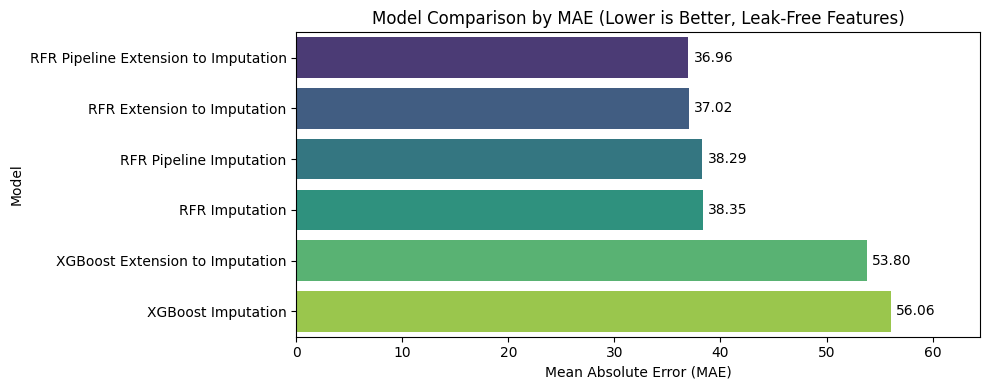

In [18]:
results_df = pd.DataFrame(results).sort_values("MAE", ascending=True).reset_index(drop=True)
display(results_df)

fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=results_df, x="MAE", y="Model", hue="Model", legend=False, palette="viridis", ax=ax)
ax.set_title("Model Comparison by MAE (Lower is Better, Leak-Free Features)")
ax.set_xlabel("Mean Absolute Error (MAE)")
ax.set_xlim(0, results_df["MAE"].max() * 1.15)
for bar in ax.patches:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"{w:.2f}", va="center")
plt.tight_layout()
plt.show()

- Tổng hợp toàn bộ kết quả đánh giá (`MAE`, `MSE`, $R^2$) của 6 cấu hình mô hình trên tập chia ngẫu nhiên 80/20, sắp xếp theo `MAE` tăng dần (mô hình chính xác nhất đứng đầu) và trực quan hóa bằng biểu đồ cột ngang kèm nhãn số cụ thể trên từng thanh.

## 11. Best Model (Standalone Leak-Free Pipeline)

In [19]:
best_model_name = results_df.iloc[0]["Model"]
print("Best performing configuration on random 80/20 split:", best_model_name)

use_indicator = "Extension" in best_model_name
best_seed = 32 if "Pipeline" in best_model_name else 1

# Standalone production-ready pipeline (automatically imputes + optionally adds missing indicators)
best_pipeline = Pipeline(
    steps=[
        ("preprocessor", SimpleImputer(strategy="mean", add_indicator=use_indicator)),
        ("model", RandomForestRegressor(n_estimators=1000, random_state=best_seed, n_jobs=-1)),
    ]
)

best_pipeline.fit(X_train, y_train)
best_preds = best_pipeline.predict(X_valid)
best_metrics = evaluate_predictions(y_valid, best_preds, f"BEST MODEL ({best_model_name})")

# Feature importances from the fitted Random Forest
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out(X_train.columns)
importances = pd.Series(
    best_pipeline.named_steps["model"].feature_importances_, index=feature_names
).sort_values(ascending=False)

print("\nTop 10 Most Important Features:")
display(importances.head(10).to_frame("importance"))

Best performing configuration on random 80/20 split: RFR Pipeline Extension to Imputation


[BEST MODEL (RFR Pipeline Extension to Imputation)] MSE: 7673.8550 | MAE: 36.9562 | R2: 0.999152

Top 10 Most Important Features:


,importance
pm3,0.932398
day,0.040125
pm2,0.013832
st,0.004449
Month,0.004270
hour,0.001418
missingindicator_st,0.000834
pres,0.000475
missingindicator_temp,0.000364
missingindicator_humd,0.000363


- **Đóng gói mô hình tối ưu & phân tích mức độ quan trọng của đặc trưng:**
  - Tự động chọn cấu hình đạt `MAE` thấp nhất (`RFR Pipeline Extension to Imputation`), huấn luyện lại thành một `Pipeline` độc lập sẵn sàng đưa vào sử dụng.
  - Trích xuất thuộc tính `feature_importances_` để xếp hạng 10 yếu tố ảnh hưởng lớn nhất tới độ ẩm đất (`sm`): đứng đầu tuyệt đối là `pm3` (chiếm **93.2%** mức độ đóng góp), tiếp theo là yếu tố thời gian `day` (**4.0%**) và `pm2` (**1.4%**).